# SMS Spam Detection: Baseline

**Dataset:** the [SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection)
(`v1` = label `ham`/`spam`, `v2` = message text). These are short SMS text messages, **not emails**:
there are no subject lines, headers or long bodies, so nothing here is evidence about email spam.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
#importing wordcloud for word visualization
from wordcloud import WordCloud
#importing nltk for natural language processing
import nltk
from nltk.corpus import stopwords

#DOWNLOADING NLTK data
# quiet=True keeps local nltk_data paths out of the outputs
for pkg in ('stopwords', 'punkt', 'punkt_tab'):
    nltk.download(pkg, quiet=True)

RANDOM_STATE = 42  # used for every split, CV and model that accepts it

In [2]:
df = pd.read_csv('../data/spam.csv', encoding='latin-1')
RAW_ROWS = len(df)
print("Raw rows:", RAW_ROWS)
df.head()

Raw rows: 5572


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [3]:
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


Data Info

In [4]:
df.info()
print(df.columns)

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 217.8 KB
Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='str')


## Rebuild messages split across the extra columns

Some messages contain `\"`, which broke the CSV quoting: the text after each comma spilled into
`Unnamed: 2`, `Unnamed: 3` and `Unnamed: 4`. These columns are continuations of `v2`, not separate
fields, so they are joined back with `","` (non-null parts only, in order) before being dropped.

In [5]:
EXTRA_COLS = ['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']
affected = df[EXTRA_COLS].notna().any(axis=1)
SPLIT_ROWS = int(affected.sum())
print("Rows with text in the extra columns:", SPLIT_ROWS)
examples = df.index[affected][:3]
with pd.option_context('display.max_colwidth', None):
    print(); print("Before:"); print(df.loc[examples, ['v2'] + EXTRA_COLS])
df['v2'] = df[['v2'] + EXTRA_COLS].apply(lambda r: ",".join(v for v in r if pd.notna(v)), axis=1)
df = df.drop(columns=EXTRA_COLS)
ROWS_AFTER_FIX = len(df)
with pd.option_context('display.max_colwidth', None):
    print(); print("After:"); print(df.loc[examples, 'v2'])
print(); print("Rows after the column fix:", ROWS_AFTER_FIX)

Rows with text in the extra columns: 50

Before:
                                                                                                                                v2  \
95   Your free ringtone is waiting to be collected. Simply text the password \MIX\" to 85069 to verify. Get Usher and Britney. FML   
281                                                                                                            \Wen u miss someone   
444                                                             \HEY HEY WERETHE MONKEESPEOPLE SAY WE MONKEYAROUND! HOWDY GORGEOUS   

                                                                       Unnamed: 2  \
95                                                                    PO Box 5249   
281   the person is definitely special for u..... But if the person is so special   
444                       HOWU DOIN? FOUNDURSELF A JOBYET SAUSAGE?LOVE JEN XXX\""   

                Unnamed: 3                      Unnamed: 4  
95    MK17 9

In [6]:
df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


 Rename the Column


In [7]:
df = df.rename(columns={'v1': 'target', 'v2': 'text'})

 Convert the target variable

In [8]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
df['target'] = encoder.fit_transform(df['target'])



In [9]:
df.head()

,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


 Check Missing values

In [10]:
df.isnull().sum()

target    0
text      0
dtype: int64

 Check Duplicate values

In [11]:
DUPLICATES = int(df.duplicated().sum())
print("Duplicate rows:", DUPLICATES)

Duplicate rows: 403


 Remove Duplicate values

In [12]:
# .copy() gives an independent frame, so later column assignments don't raise SettingWithCopyWarning
df = df.drop_duplicates(keep='first').copy()

 Shape of the Dataset

In [13]:
df.shape

(5169, 2)

EXPLORATORY DATA ANALYSIS



 Percentage of Ham and Spam

In [14]:
values = df['target'].value_counts().sort_index()
print("Rows after removing duplicates:", len(df))
for label, name in [(0, 'ham'), (1, 'spam')]:
    print(f"{name}: {values[label]} ({values[label] / values.sum() * 100:.2f}%)")

Rows after removing duplicates: 5169
ham: 4516 (87.37%)
spam: 653 (12.63%)


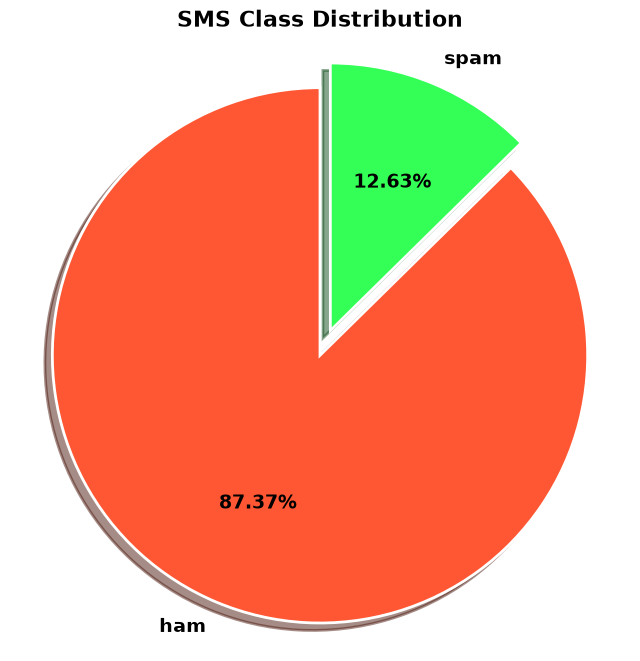

In [15]:
import matplotlib.pyplot as plt
colors = ['#FF5733', '#33FF57']
# Define the explode parameter to create a gap between slices
explode = (0, 0.1)  # Explode the second slice (spam) by 10%
fig , ax = plt.subplots(figsize=(8,8))
ax.set_facecolor('white')
wedges , texts , autotexts = ax.pie(
    values, labels = ['ham' , 'spam'],
    autopct='%0.2f%%',
    startangle = 90,
    colors = colors,
    wedgeprops={'linewidth': 2, 'edgecolor': 'white'},
    explode=explode,
    shadow = True

)
# Customize text properties
for text, autotext in zip(texts, autotexts):
    text.set(size=14, weight='bold')
    autotext.set(size=14, weight='bold')

ax.set_title('SMS Class Distribution', fontsize=16, fontweight='bold')
# Equal aspect ratio ensures that pie is drawn as a circle
ax.axis('equal')

# Show the pie chart
plt.show()

Ham far outnumbers spam (counts printed above), so the classes are imbalanced. Accuracy alone is therefore a weak metric.

Text Length and Structure Analysis

In [16]:
df['num_characters'] = df['text'].apply(len)
df['num_words'] = df['text'].apply(lambda x: len(nltk.word_tokenize(x)))
df['num_sentence'] = df['text'].apply(lambda x: len(nltk.sent_tokenize(x)))

In [17]:
df[['num_characters', 'num_words', 'num_sentence']].describe()


,num_characters,num_words,num_sentence
count,5169.000000,5169.000000,5169.000000
mean,79.538982,18.610563,1.971948
std,58.480098,13.412622,1.456472
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,61.000000,15.000000,1.000000
75%,119.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


 Summary Statistics for Legitimate Messages

In [18]:
#ham
df[df['target'] == 0][['num_characters', 'num_words', 'num_sentence']].describe()

,num_characters,num_words,num_sentence
count,4516.000000,4516.000000,4516.000000
mean,71.060895,17.287201,1.826395
std,56.711542,13.601466,1.392743
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,53.000000,13.000000,1.000000
75%,92.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


Summary Statistics for Spam Messages

In [19]:
#spam
df[df['target'] == 1][['num_characters', 'num_words', 'num_sentence']].describe()

,num_characters,num_words,num_sentence
count,653.000000,653.000000,653.00000
mean,138.171516,27.762634,2.97856
std,29.916827,6.987742,1.49010
min,13.000000,2.000000,1.00000
25%,132.000000,25.000000,2.00000
50%,149.000000,29.000000,3.00000
75%,157.000000,32.000000,4.00000
max,224.000000,46.000000,9.00000


Character Length Distribution for Legitimate and Spam Messages

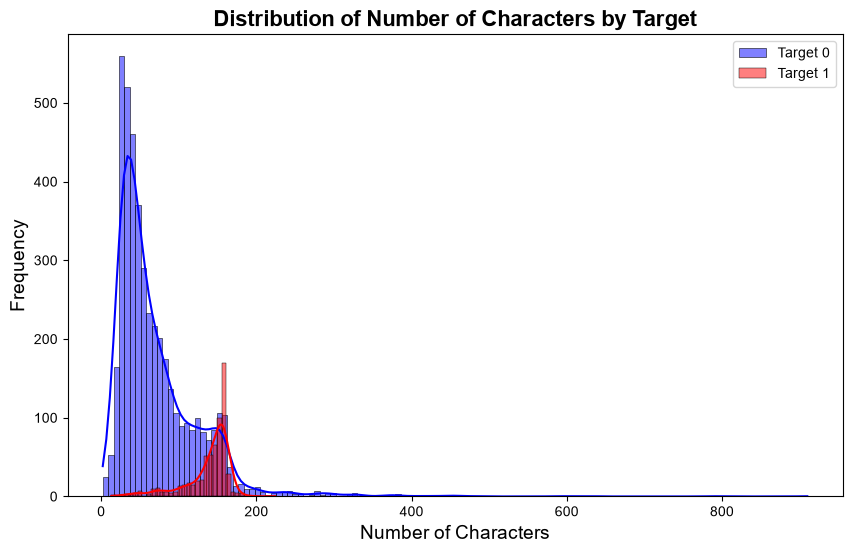

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
# Plot the histogram for target 0 in blue
sns.histplot(df[df['target'] == 0]['num_characters'], color = 'blue', kde = True, label = 'Target 0')

# Plot the histogram for target 1 in red
sns.histplot(df[df['target'] == 1]['num_characters'], color='red', label='Target 1', kde=True)
plt.xlabel('Number of Characters', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
plt.title('Distribution of Number of Characters by Target', fontsize=16, fontweight='bold')
plt.legend()
# Customize the appearance of the plot
sns.set(style='whitegrid')  # Add a white grid background
plt.show()


paitplot for data in visualization

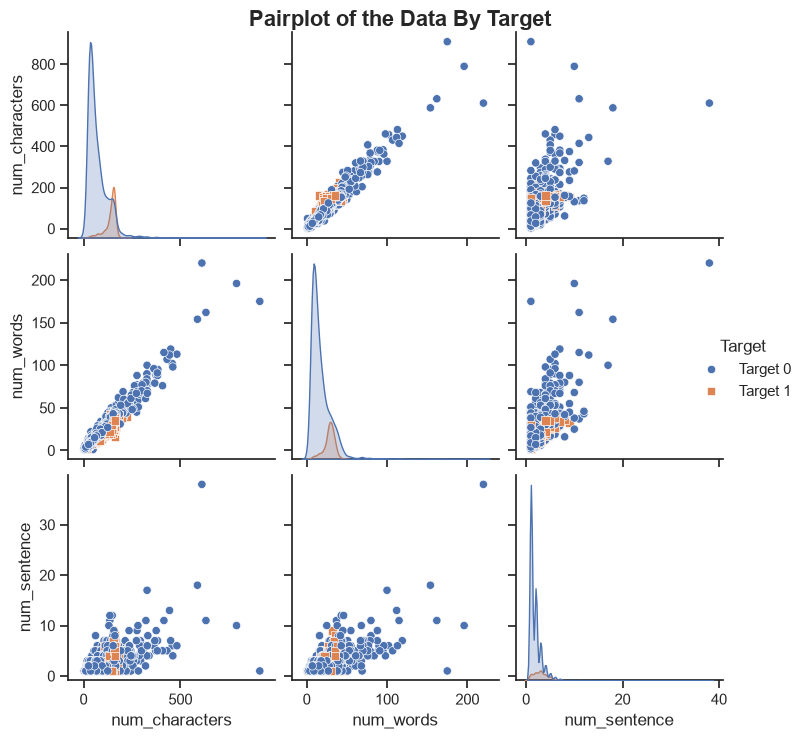

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style = 'ticks', color_codes = True)
g = sns.pairplot(df , hue = 'target', diag_kind = 'kde' , markers= ["o", "s"])

g.fig.suptitle("Pairplot of the Data By Target" , fontsize = 16 , fontweight = 'bold')
plt.subplots_adjust(top=0.95)#adjust the position title
g._legend.set_title('Target ')
for t, l in  zip(g._legend.texts , ["Target 0 " , "Target 1 " ]):
    t.set_text(l)

plt.show()

Correlation

In [22]:
df[['target','num_characters', 'num_words', 'num_sentence']].corr()

,target,num_characters,num_words,num_sentence
target,1.000000,0.381287,0.259494,0.262834
num_characters,0.381287,1.000000,0.965654,0.622124
num_words,0.259494,0.965654,1.000000,0.678390
num_sentence,0.262834,0.622124,0.678390,1.000000


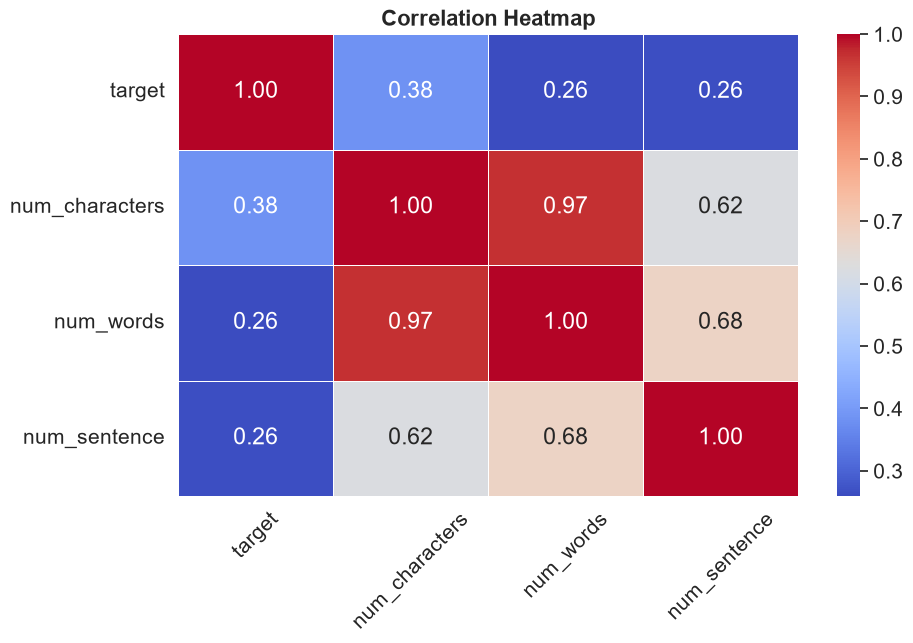

In [23]:
correlation_matrix = df[['target','num_characters', 'num_words', 'num_sentence']].corr()
plt.figure(figsize=(10,6))
sns.set(font_scale=1.4)
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5 , fmt = '.2f')

plt.title("Correlation Heatmap", fontsize=16, fontweight='bold')
plt.xticks(rotation=45)
plt.show()

Data Preprocessing


In [24]:
from nltk.stem.porter import PorterStemmer
ps = PorterStemmer()
STOPWORDS = set(stopwords.words('english'))

def transform_text(text, remove_stopwords=False):
    # lowercase -> tokenize -> keep alphanumeric tokens -> (optionally drop English stopwords) -> Porter stem
    tokens = [t for t in nltk.word_tokenize(text.lower()) if t.isalnum()]
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOPWORDS]
    return " ".join(ps.stem(t) for t in tokens)

In [25]:
transform_text('Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...')

'go until jurong point crazi avail onli in bugi n great world la e buffet cine there got amor wat'

creating a new column :  'transformed_text'

In [26]:
# transform_text is stateless (lowercase, tokenize, keep alphanumerics, Porter stem): each message is
# transformed on its own, nothing is learned from other rows, so applying it before the split is not leakage.
# Variant (a) stem only -> 'transformed_text'; variant (b) stem + stopword removal -> 'transformed_text_nostop'.
df['transformed_text'] = df['text'].apply(transform_text)
df['transformed_text_nostop'] = df['text'].apply(transform_text, remove_stopwords=True)

In [27]:
df.head()

,target,text,num_characters,num_words,num_sentence,transformed_text,transformed_text_nostop
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go until jurong point crazi avail onli in bugi...,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri in 2 a wkli comp to win fa cup fina...,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say so earli hor u c alreadi then say,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah i do think he goe to usf he live around he...,nah think goe usf live around though


In [28]:
import wordcloud
import PIL

print("WordCloud version:", wordcloud.__version__)
print("Pillow version:", PIL.__version__)
# Pillow version: 9.4.0 is necessary for compatibility with python versions before 9. anymore version 9 is not supported

WordCloud version: 1.9.6
Pillow version: 13.0.0


 Word Cloud for Spam Messages

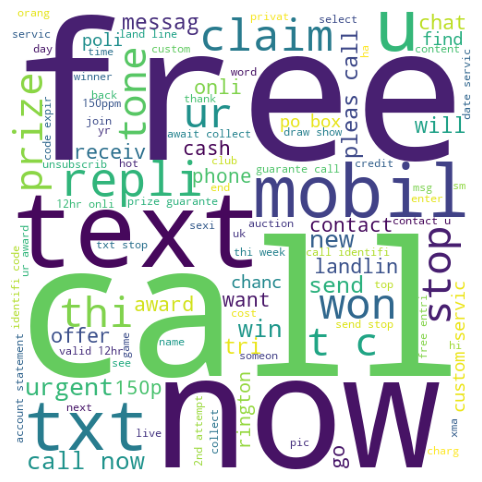

In [29]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

wc = WordCloud(width=500, height=500, min_font_size=10, background_color='white')
spam_wc = wc.generate(df[df['target'] == 1]['transformed_text'].str.cat(sep=" "))
plt.figure(figsize=(15, 6))
plt.imshow(spam_wc)
plt.axis("off")
plt.show()


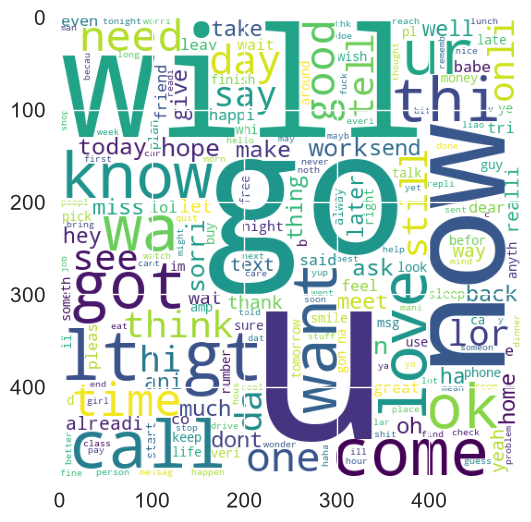

In [30]:
ham_wc = wc.generate(df[df['target'] == 0]['transformed_text'].str.cat(sep = " "))
plt.figure(figsize = (15,6))
plt.imshow(ham_wc)
plt.show()

In [31]:
spam_carpos = []
for sentence in df[df['target'] == 1]['transformed_text'].tolist():
    for word in sentence.split():
        spam_carpos.append(word)

In [32]:
from collections import Counter 
filter_df = pd.DataFrame(Counter(spam_carpos).most_common(30))


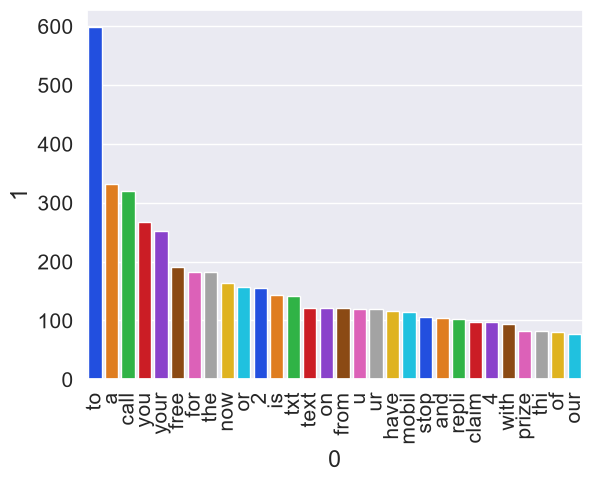

In [33]:
sns.barplot(data=filter_df, x=0, y=1, hue=0, palette='bright', legend=False)
plt.xticks(rotation = 90)
plt.show()

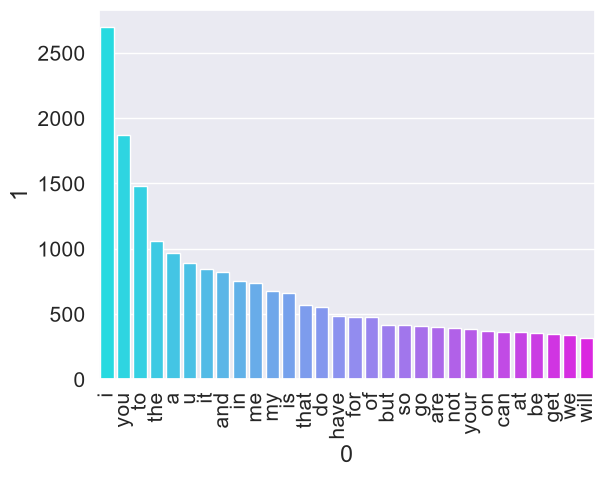

In [34]:
ham_carpos = []
for sentence in df[df['target'] == 0]['transformed_text'].tolist():
    for word in sentence.split():
        ham_carpos.append(word)
filter_ham_df = pd.DataFrame(Counter(ham_carpos).most_common(30))
sns.barplot(data=filter_ham_df, x=0, y=1, hue=0, palette='cool', legend=False)
plt.xticks(rotation = 90)
plt.show()

Text vectorizer (TF-IDF)

In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

def make_pipeline(model):
    # TF-IDF lives inside the Pipeline, so it is only ever fit on the training rows/folds it is given.
    return Pipeline([("tfidf", TfidfVectorizer(max_features=3000)), ("clf", model)])

 Dependent and Independent Variable

In [36]:
from sklearn.model_selection import train_test_split

y = df['target'].values
# Split FIRST (stratified). The test rows are not used again until the single final evaluation.
train_idx, test_idx = train_test_split(df.index, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
X_train, X_test = df.loc[train_idx, 'transformed_text'], df.loc[test_idx, 'transformed_text']
y_train, y_test = df.loc[train_idx, 'target'].values, df.loc[test_idx, 'target'].values
print("Train rows:", len(train_idx), "| Test rows:", len(test_idx))

Train rows: 4135 | Test rows: 1034


importing the models


In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier 



initialise the models 


In [38]:
# Original 11 models and parameters (kept for comparability); random_state=RANDOM_STATE wherever accepted.
svc = SVC(kernel='sigmoid', gamma=1.0, random_state=RANDOM_STATE)
knc = KNeighborsClassifier()
mnb = MultinomialNB()
dtc = DecisionTreeClassifier(random_state=RANDOM_STATE)
lrc = LogisticRegression(solver='liblinear', l1_ratio=1, random_state=RANDOM_STATE)  # l1_ratio=1 == penalty='l1' (deprecated in sklearn 1.8)
rfc = RandomForestClassifier(n_estimators=50, random_state=RANDOM_STATE)
abc = AdaBoostClassifier(n_estimators=50, random_state=RANDOM_STATE)
bc = BaggingClassifier(n_estimators=54, random_state=RANDOM_STATE)
etc = ExtraTreesClassifier(n_estimators=50, random_state=RANDOM_STATE)
gbdt = GradientBoostingClassifier(n_estimators=54, random_state=RANDOM_STATE)
xgb = XGBClassifier(n_estimators=50, random_state=RANDOM_STATE)

 Dictionary of the Models

In [39]:
models = {
    'SVC': svc,
    'KNN': knc,
    'NB': mnb,
    'DT': dtc,
    'LR': lrc,
    'RF': rfc,
    'Adaboost': abc,
    'Bgc': bc,
    'ETC': etc,
    'GBDT': gbdt,
    'xgb': xgb
    
}

## Stratified 5-fold cross-validation (training set only)

Every model is evaluated as `Pipeline(TF-IDF -> model)` so TF-IDF is refit inside each training fold.

In [40]:
import os
from sklearn.model_selection import StratifiedKFold, cross_validate

SCORING = ['accuracy', 'precision', 'recall', 'f1', 'average_precision']
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, model in models.items():
    scores = cross_validate(make_pipeline(model), X_train, y_train, cv=cv, scoring=SCORING)
    row = {'model': name}
    for metric in SCORING:
        row[f'{metric}_mean'] = scores[f'test_{metric}'].mean()
        row[f'{metric}_std'] = scores[f'test_{metric}'].std()
    rows.append(row)

cv_results = pd.DataFrame(rows).sort_values('average_precision_mean', ascending=False).reset_index(drop=True)
os.makedirs('../results', exist_ok=True)
cv_results.to_csv('../results/cv_results.csv', index=False)
cv_results.round(4)

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,average_precision_mean,average_precision_std
0,SVC,0.9785,0.0016,0.9767,0.0204,0.8506,0.0229,0.9088,0.0073,0.9608,0.0090
1,RF,0.9695,0.0075,0.9923,0.0106,0.7645,0.0546,0.8626,0.0375,0.9601,0.0082
2,ETC,0.9736,0.0066,0.9855,0.0094,0.8028,0.0455,0.8843,0.0314,0.9555,0.0106
3,xgb,0.9698,0.0070,0.9522,0.0256,0.8006,0.0444,0.8693,0.0329,0.9423,0.0202
4,NB,0.9591,0.0050,1.0000,0.0000,0.6764,0.0390,0.8063,0.0277,0.9413,0.0114
5,GBDT,0.9579,0.0053,0.9703,0.0133,0.6877,0.0414,0.8042,0.0292,0.9180,0.0164
6,LR,0.9603,0.0039,0.9343,0.0216,0.7396,0.0521,0.8239,0.0230,0.9103,0.0061
7,Bgc,0.9642,0.0049,0.8864,0.0296,0.8237,0.0439,0.8527,0.0229,0.9031,0.0243
8,Adaboost,0.9383,0.0069,0.8715,0.0161,0.5997,0.0565,0.7092,0.0402,0.8416,0.0223
9,DT,0.9514,0.0064,0.8167,0.0207,0.7930,0.0506,0.8039,0.0310,0.6761,0.0410


## Model selection (rule fixed before looking at results)

Selected model = highest mean CV `average_precision` (PR-AUC). Models within 0.001 of the best are
treated as tied, and the tie is broken by higher mean CV recall.

In [41]:
top_ap = cv_results['average_precision_mean'].max()
tied = cv_results[cv_results['average_precision_mean'] >= top_ap - 0.001]
SELECTED = tied.sort_values('recall_mean', ascending=False).iloc[0]['model']
print("Models within 0.001 of the best PR-AUC:", list(tied['model']))
print("Selected model:", SELECTED)

Models within 0.001 of the best PR-AUC: ['SVC', 'RF']
Selected model: SVC


## Experiment: stopword removal

Variant (a) stem only vs (b) stem + English stopword removal, compared with 5-fold CV on the **training set
only**, using the selected model. The variant with the higher mean CV average_precision is used from here on
(ties keep the simpler variant (a)). The 11-model comparison above uses variant (a), the original preprocessing.

In [42]:
from sklearn.model_selection import cross_val_score

VARIANTS = {'stem_only': 'transformed_text', 'stem_plus_stopword_removal': 'transformed_text_nostop'}
variant_ap = {}
for variant, col in VARIANTS.items():
    ap = cross_val_score(make_pipeline(models[SELECTED]), df.loc[train_idx, col], y_train,
                         cv=cv, scoring='average_precision')
    variant_ap[variant] = {'mean': ap.mean(), 'std': ap.std()}
    print(f"{variant}: mean CV average_precision = {ap.mean():.4f} (std {ap.std():.4f})")

PREPROCESSING = ('stem_plus_stopword_removal'
                 if variant_ap['stem_plus_stopword_removal']['mean'] > variant_ap['stem_only']['mean'] else 'stem_only')
X_train_sel, X_test_sel = df.loc[train_idx, VARIANTS[PREPROCESSING]], df.loc[test_idx, VARIANTS[PREPROCESSING]]
print("Chosen preprocessing variant:", PREPROCESSING)

stem_only: mean CV average_precision = 0.9608 (std 0.0090)
stem_plus_stopword_removal: mean CV average_precision = 0.9453 (std 0.0106)
Chosen preprocessing variant: stem_only


## Why precision alone misleads

In [43]:
knn = pd.read_csv('../results/cv_results.csv').set_index('model').loc['KNN']
print(f"KNN mean CV precision: {knn['precision_mean']:.4f}")
print(f"KNN mean CV recall:    {knn['recall_mean']:.4f}")
print(f"=> KNN looks precise, yet it catches only {knn['recall_mean'] * 100:.1f}% of spam: "
      "when a model flags very little, the few flags it raises can all be right.")

KNN mean CV precision: 1.0000
KNN mean CV recall:    0.3141
=> KNN looks precise, yet it catches only 31.4% of spam: when a model flags very little, the few flags it raises can all be right.


## Decision threshold from out-of-fold scores (training set only)

Use out-of-fold scores of the selected pipeline on the training set and take the **lowest** threshold whose
precision is at least 0.98. If none reaches 0.98, keep the default threshold.

In [44]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

TARGET_PRECISION = 0.98
sel_pipe = make_pipeline(clone(models[SELECTED]))
SCORE_METHOD = 'predict_proba' if hasattr(sel_pipe, 'predict_proba') else 'decision_function'
DEFAULT_THRESHOLD = 0.5 if SCORE_METHOD == 'predict_proba' else 0.0

def spam_scores(output):
    return output[:, 1] if SCORE_METHOD == 'predict_proba' else output

oof = spam_scores(cross_val_predict(sel_pipe, X_train_sel, y_train, cv=cv, method=SCORE_METHOD))
prec, rec, thr = precision_recall_curve(y_train, oof)
ok = thr[prec[:-1] >= TARGET_PRECISION]
THRESHOLD_TUNED = ok.size > 0
THRESHOLD = float(ok.min()) if THRESHOLD_TUNED else DEFAULT_THRESHOLD
print("Score method:", SCORE_METHOD, "| default threshold:", DEFAULT_THRESHOLD)
print("Tuned threshold:" if THRESHOLD_TUNED else f"No threshold reaches precision {TARGET_PRECISION}; using default:", THRESHOLD)

Score method: decision_function | default threshold: 0.0
Tuned threshold: 0.04471150912114341


## Final evaluation on the held-out test set (done exactly once)

In [45]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix)

sel_pipe.fit(X_train_sel, y_train)
test_scores = spam_scores(getattr(sel_pipe, SCORE_METHOD)(X_test_sel))

def evaluate(y_pred):
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    return {'accuracy': accuracy_score(y_test, y_pred), 'precision': precision_score(y_test, y_pred),
            'recall': recall_score(y_test, y_pred), 'f1': f1_score(y_test, y_pred),
            'average_precision': average_precision_score(y_test, test_scores),
            'confusion_matrix': {'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)}}

test_metrics = {'default_threshold': evaluate(sel_pipe.predict(X_test_sel)),
                'tuned_threshold': evaluate((test_scores >= THRESHOLD).astype(int))}
pd.DataFrame({k: {m: v for m, v in d.items() if m != 'confusion_matrix'} | d['confusion_matrix']
              for k, d in test_metrics.items()}).round(4)

,default_threshold,tuned_threshold
accuracy,0.9816,0.9807
precision,0.9828,0.9826
recall,0.8702,0.8626
f1,0.9231,0.9187
average_precision,0.9725,0.9725
tn,901.0000,901.0000
fp,2.0000,2.0000
fn,17.0000,18.0000
tp,114.0000,113.0000


In [46]:
print("Selected model:", SELECTED, models[SELECTED])
print("Selection rule: highest mean CV PR-AUC; ties within 0.001 broken by mean CV recall")
print(f"Threshold: {THRESHOLD} ({'tuned for OOF precision >= 0.98' if THRESHOLD_TUNED else 'default'})")
for k, d in test_metrics.items():
    print(f"Test @ {k}: " + ", ".join(f"{m}={v:.4f}" for m, v in d.items() if m != 'confusion_matrix'),
          "| confusion matrix:", d['confusion_matrix'])

Selected model: SVC SVC(gamma=1.0, kernel='sigmoid', random_state=42)
Selection rule: highest mean CV PR-AUC; ties within 0.001 broken by mean CV recall
Threshold: 0.04471150912114341 (tuned for OOF precision >= 0.98)
Test @ default_threshold: accuracy=0.9816, precision=0.9828, recall=0.8702, f1=0.9231, average_precision=0.9725 | confusion matrix: {'tn': 901, 'fp': 2, 'fn': 17, 'tp': 114}
Test @ tuned_threshold: accuracy=0.9807, precision=0.9826, recall=0.8626, f1=0.9187, average_precision=0.9725 | confusion matrix: {'tn': 901, 'fp': 2, 'fn': 18, 'tp': 113}


## Save the pipeline and metrics

In [47]:
import json, sys, platform, datetime, importlib.metadata
import joblib

os.makedirs('../models', exist_ok=True)
joblib.dump(sel_pipe, '../models/spam_pipeline.joblib')

def jsonable(v):
    return v if isinstance(v, (bool, int, float, str, type(None))) else repr(v)

counts = df['target'].value_counts().sort_index()
metrics = {
    'dataset': 'SMS Spam Collection (data/spam.csv)',
    'rows': {'raw': RAW_ROWS, 'rows_with_split_text_rebuilt': SPLIT_ROWS, 'after_column_fix': ROWS_AFTER_FIX,
             'duplicates_removed': DUPLICATES, 'final': len(df)},
    'class_counts': {'ham': int(counts[0]), 'spam': int(counts[1])},
    'split': {'train': len(train_idx), 'test': len(test_idx), 'test_size': 0.2, 'stratified': True},
    'random_state': RANDOM_STATE,
    'preprocessing': {'chosen': PREPROCESSING, 'cv_average_precision': variant_ap},
    'cv': {'n_splits': cv.get_n_splits(), 'preprocessing': 'stem_only',
           'results': cv_results.to_dict(orient='records')},
    'selection_rule': 'highest mean CV average_precision; ties within 0.001 broken by higher mean CV recall',
    'selected_model': {'name': SELECTED, 'class': type(models[SELECTED]).__name__,
                       'params': {k: jsonable(v) for k, v in models[SELECTED].get_params().items()},
                       'tfidf_max_features': 3000},
    'threshold': {'score_method': SCORE_METHOD, 'default': DEFAULT_THRESHOLD, 'tuned': THRESHOLD,
                  'tuning_succeeded': bool(THRESHOLD_TUNED), 'target_oof_precision': TARGET_PRECISION},
    'test_metrics': test_metrics,
    'versions': {'python': platform.python_version(),
                 **{p: importlib.metadata.version(p) for p in
                    ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'nltk', 'matplotlib', 'seaborn', 'wordcloud', 'joblib']}},
    'generated_utc': datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds'),
}
with open('../results/metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2)
print("Saved ../models/spam_pipeline.joblib and ../results/metrics.json")

Saved ../models/spam_pipeline.joblib and ../results/metrics.json


## Predict new messages

In [48]:
def predict(messages, model_path='../models/spam_pipeline.joblib', metrics_path='../results/metrics.json'):
    pipe = joblib.load(model_path)
    with open(metrics_path) as f:
        m = json.load(f)
    text = [transform_text(msg, remove_stopwords=m['preprocessing']['chosen'] == 'stem_plus_stopword_removal')
            for msg in messages]
    scores = spam_scores(getattr(pipe, m['threshold']['score_method'])(text))
    return ['spam' if s >= m['threshold']['tuned'] else 'ham' for s in scores]

examples = ["WINNER!! You have been selected to receive a cash prize. Call now to claim, T&Cs apply",
            "Are we still meeting for lunch tomorrow?",
            "Free entry to win a new mobile phone! Text WIN to claim your reward"]
for msg, label in zip(examples, predict(examples)):
    print(f"{label:>4}  <- {msg}")

spam  <- WINNER!! You have been selected to receive a cash prize. Call now to claim, T&Cs apply
 ham  <- Are we still meeting for lunch tomorrow?
spam  <- Free entry to win a new mobile phone! Text WIN to claim your reward
